# Adaptive long memory in volatility forecasting
### Results and interpretation — reproducible notebook

This notebook rebuilds every key figure and table of the master's thesis **from the committed
CSV results** and explains what each number means. No heavy computation is required: the
estimators (R/S, GPH, CUSUM, HAR-RV, attention regimes) were run beforehand and their output
lives in `results/`.

**Research question.** Volatility of financial series shows *long memory*: autocorrelations
decay as a power law, so the past keeps influencing the present. The central finding is that
this memory is **non-stationary** — it collapses in crises. A local estimate of the memory
strength `d̂(t)` therefore carries predictive value and can steer a transformer's attention
(**Memory-Adaptive Attention**).

**Content**
1. Setup and inventory of the computed results
2. Result 1 — long memory lives in volatility, not in returns
3. Result 2 — the memory strength is not constant over time
4. Result 3 — CUSUM test: structural breaks and crisis vs. calm regimes
5. Result 4 — local memory improves the HAR-RV forecast
6. Result 5 — static attention mechanisms degrade when memory strengthens
7. Practical part — from volatility forecast to VaR/ES
8. Conclusions

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

REPO = os.path.abspath(os.path.join('..', '.')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
RES = os.path.join(REPO, 'results')
FIG = os.path.join(REPO, 'figures')
os.makedirs(FIG, exist_ok=True)

BLUE, NAVY, MID, SOFT, PALE, INK = '#255C8B', '#0E4B74', '#4A8FC7', '#7FB2D9', '#A9C9E4', '#1B3A57'

plt.rcParams.update({
    'font.size': 11, 'axes.grid': True, 'grid.alpha': .25, 'grid.color': '#C9D9E6',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8FA6BA',
    'axes.labelcolor': INK, 'xtick.color': '#4A5A6A', 'ytick.color': '#4A5A6A',
    'text.color': INK, 'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlecolor': INK,
})

ASSETS = ['META', 'BA', 'JPM', 'AAPL', 'MSFT', 'BTC', 'ETH', 'EURUSD', 'USDJPY', 'GBPUSD']
CRISES = [('2020-02-19', '2020-04-01'), ('2022-03-01', '2022-10-31'), ('2023-03-01', '2023-05-31')]
print('repository root :', REPO)
print('results folder  :', RES)

repository root : C:\diploma\github\memory-adaptive-volatility
results folder  : C:\diploma\github\memory-adaptive-volatility\results


In [2]:
files = sorted(glob.glob(os.path.join(RES, '*.csv')))
inventory = []
for f in files:
    df = pd.read_csv(f)
    inventory.append({'file': os.path.basename(f), 'rows': len(df), 'cols': ', '.join(df.columns[:6])})
display(pd.DataFrame(inventory).style.hide(axis='index'))

file,rows,cols
attention_regimes.csv,9,"mechanism, regime, RMSE, MAE, TheilU2, R2"
har_memory_comparison.csv,10,"asset, n_test, mse_base, mse_ext, qlike_base, qlike_ext"
rolling_AAPL_abs_ret.csv,30,"start_idx, end_idx, start_date, end_date, H, d"
rolling_AAPL_log_ret.csv,30,"start_idx, end_idx, start_date, end_date, H, d"
rolling_AAPL_rv.csv,30,"start_idx, end_idx, start_date, end_date, H, d"
rolling_BA_abs_ret.csv,30,"start_idx, end_idx, start_date, end_date, H, d"
rolling_BA_log_ret.csv,30,"start_idx, end_idx, start_date, end_date, H, d"
rolling_BA_rv.csv,30,"start_idx, end_idx, start_date, end_date, H, d"
rolling_BTC_abs_ret.csv,53,"start_idx, end_idx, start_date, end_date, H, d"
rolling_BTC_log_ret.csv,53,"start_idx, end_idx, start_date, end_date, H, d"


---
## Result 1 — long memory lives in volatility, not in returns

We compare three proxies for every asset: the log return itself, its absolute value, and
realized volatility (RV). Long memory means slowly decaying autocorrelations, i.e. a
clearly positive Hurst exponent `H = d + 1/2`.

* **Returns:** `d ≈ 0` — the memory is absent, prices behave like a short-memory process.
* **RV:** `d ∈ [0.42; 0.56]`, `H ≈ 0.90–0.95` — the memory is strong and stable.

That is why the modelling object is volatility, not price.

In [3]:
s = pd.read_csv(os.path.join(RES, 'rolling_summary.csv'))
piv = (s[s.proxy.isin(['log_ret', 'abs_ret', 'rv'])]
       .pivot(index='asset', columns='proxy', values='d_mean')
       .reindex(ASSETS))
h_mean = (s[s.proxy == 'rv'].set_index('asset')['H_mean'].reindex(ASSETS))
display(piv.round(3))
print('\nH (RV), mean per asset:')
print(h_mean.round(3).to_string())

proxy,abs_ret,log_ret,rv
asset,,,
META,0.127,0.071,0.426
BA,0.238,0.010,0.538
JPM,0.216,-0.036,0.539
AAPL,0.238,0.032,0.556
MSFT,0.213,-0.055,0.548
BTC,0.201,0.021,0.419
ETH,0.140,0.017,0.430
EURUSD,0.195,0.033,0.506
USDJPY,0.253,0.011,0.516



H (RV), mean per asset:
asset
META      0.897
BA        0.937
JPM       0.911
AAPL      0.951
MSFT      0.948
BTC       0.905
ETH       0.912
EURUSD    0.932
USDJPY    0.915
GBPUSD    0.939


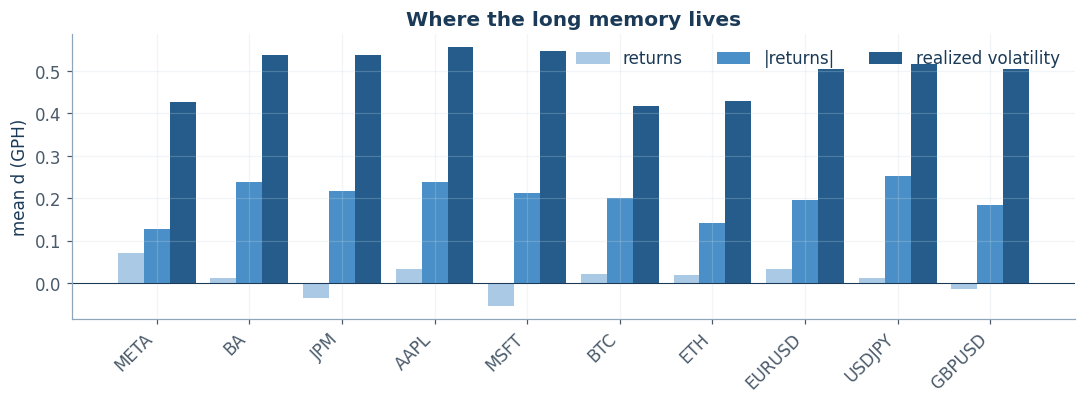

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(ASSETS)); w = .28
for j, (proxy, color, label) in enumerate([('log_ret', PALE, 'returns'),
                                           ('abs_ret', MID, '|returns|'),
                                           ('rv', BLUE, 'realized volatility')]):
    ax.bar(x + (j - 1) * w, piv[proxy].values, w, color=color, label=label)
ax.set_xticks(x); ax.set_xticklabels(ASSETS, rotation=45, ha='right')
ax.set_ylabel('mean d (GPH)'); ax.axhline(0, color=INK, lw=.7)
ax.set_title('Where the long memory lives')
ax.legend(frameon=False, ncol=3)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'nb_memory_localization.png')); plt.show()

---
## Result 2 — the memory strength is not constant over time

The same estimator applied to a sliding window (500 observations, step 25) produces a
**trajectory** `d(t)` instead of a single number. In calm periods `d` sits near 0.65–0.75;
in the 2022 rate-hike cycle it drops to 0.30–0.45 — the memory "collapses" by a factor of
almost three. This is exactly the behaviour a static parameter cannot represent.

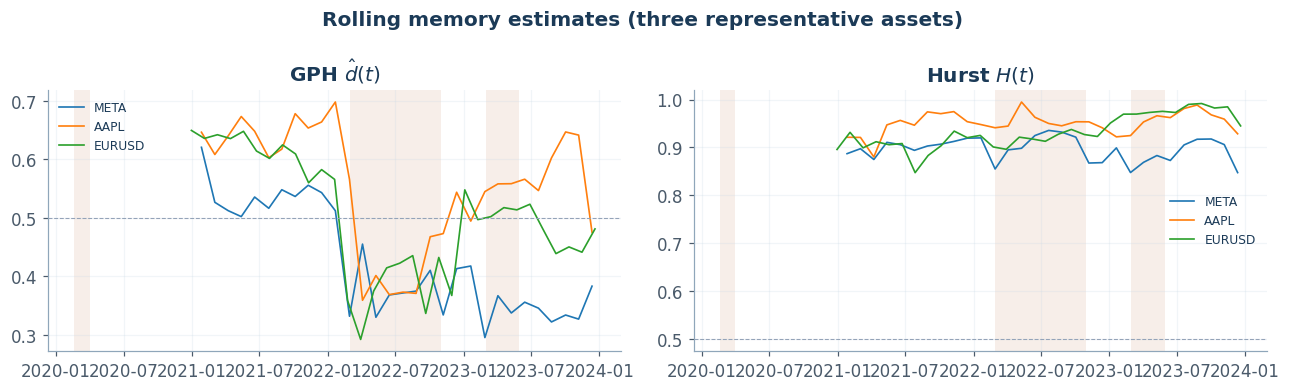

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for a in ['META', 'AAPL', 'EURUSD']:
    r = pd.read_csv(os.path.join(RES, f'rolling_{a}_rv.csv'))
    axes[0].plot(pd.to_datetime(r['end_date']), r['d'], lw=1.1, label=a)
    axes[1].plot(pd.to_datetime(r['end_date']), r['H'], lw=1.1, label=a)
for ax, ttl in zip(axes, [r'GPH $\hat d(t)$', r'Hurst $H(t)$']):
    for c0, c1 in CRISES:
        ax.axvspan(pd.Timestamp(c0), pd.Timestamp(c1), color='#C0764B', alpha=.12, lw=0)
    ax.axhline(.5, color='#94A3B8', ls='--', lw=.7)
    ax.set_title(ttl); ax.legend(frameon=False, fontsize=8)
fig.suptitle('Rolling memory estimates (three representative assets)', fontweight='bold')
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'nb_rolling_memory.png')); plt.show()

---
## Result 3 — CUSUM test: structural breaks and crisis vs. calm regimes

The CUSUM test detects level shifts in the trajectory `d(t)`; the Welch test with bootstrap
compares the mean memory in crisis and calm windows. Significant shifts are found for
**7 of 10 assets**, and on average `d` falls from **0.52 to 0.45** in crisis periods.

,d_calm_mean,d_crisis_mean,cusum_p,t_p,cusum_sig
asset,,,,,
META,0.4462,0.3858,0.0000,0.0496,True
BA,0.5676,0.4800,0.0000,0.0880,True
JPM,0.5740,0.4691,0.0000,0.0207,True
AAPL,0.5982,0.4720,0.0031,0.0081,True
MSFT,0.5815,0.4801,0.0000,0.0371,True
BTC,0.4197,0.4164,0.0560,0.9064,False
ETH,0.4236,0.4431,0.4479,0.1594,False
EURUSD,0.5514,0.4304,0.0001,0.0006,True
USDJPY,0.5503,0.4583,0.0007,0.0460,True


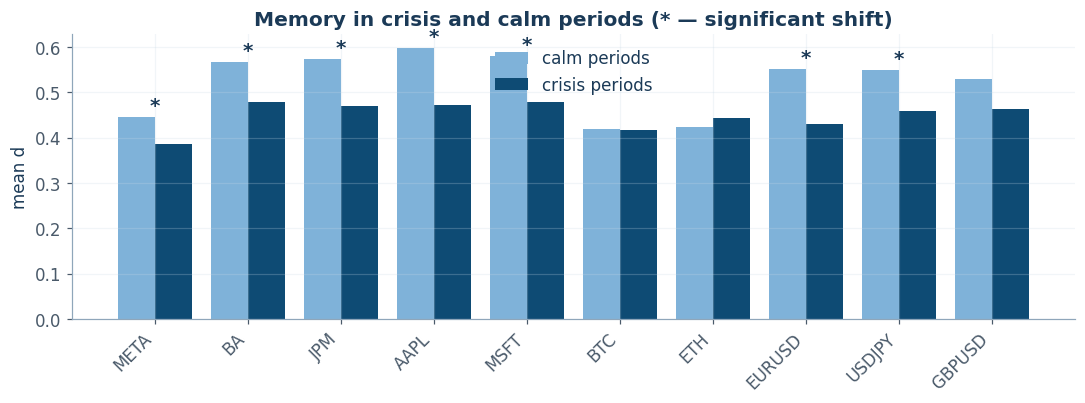

significant CUSUM shifts: 7 of 10
mean calm d  : 0.524
mean crisis d: 0.450


In [6]:
b = pd.read_csv(os.path.join(RES, 'structural_breaks.csv')).set_index('asset').reindex(ASSETS)
show = b[['d_calm_mean', 'd_crisis_mean', 'cusum_p', 't_p']].copy()
show['cusum_sig'] = b['cusum_sig']
display(show.round(4))

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(ASSETS)); w = .4
calm = b['d_calm_mean'].values; cris = b['d_crisis_mean'].values
ax.bar(x - w/2, calm, w, color=SOFT, label='calm periods')
ax.bar(x + w/2, cris, w, color=NAVY, label='crisis periods')
for i, a in enumerate(ASSETS):
    if b['cusum_sig'].iloc[i]:
        ax.text(i, max(calm[i], cris[i]) + .012, '*', ha='center', fontsize=13, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(ASSETS, rotation=45, ha='right')
ax.set_ylabel('mean d'); ax.set_title('Memory in crisis and calm periods (* — significant shift)')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'nb_crisis_vs_calm.png')); plt.show()

print('significant CUSUM shifts:', int(b['cusum_sig'].sum()), 'of', len(b))
print('mean calm d  : %.3f' % calm.mean())
print('mean crisis d: %.3f' % cris.mean())

---
## Result 4 — local memory improves the HAR-RV forecast

We add the local level `d̂_t` and its increment `Δd̂_t` to the HAR-RV baseline and compare
the two models in a walk-forward scheme (expanding window, OLS re-estimated at every step).

* **MSE improves for all 10 assets**, average **+7.1 %**.
* **QLIKE improves for 8 of 10 assets**, average **+1.8 %**.
* The largest gains concentrate in the most volatile instruments (META +26.9 %, BTC +16.1 %).
* Two assets show a small QLIKE degradation (MSFT, GBPUSD) — the effect of a weak signal is
  noisy when the predictor adds almost nothing.

,"dMSE, %","dQLIKE, %"
asset,,
META,26.91,3.76
BA,0.98,0.64
JPM,1.03,4.11
AAPL,2.25,0.94
MSFT,0.28,-5.68
BTC,16.09,5.42
ETH,2.42,2.11
EURUSD,8.46,3.84
USDJPY,6.39,3.07


assets with MSE gain > 0 : 10 of 10
assets with QLIKE gain > 0: 8 of 10
mean dMSE  : +7.1 %
mean dQLIKE: +1.8 %


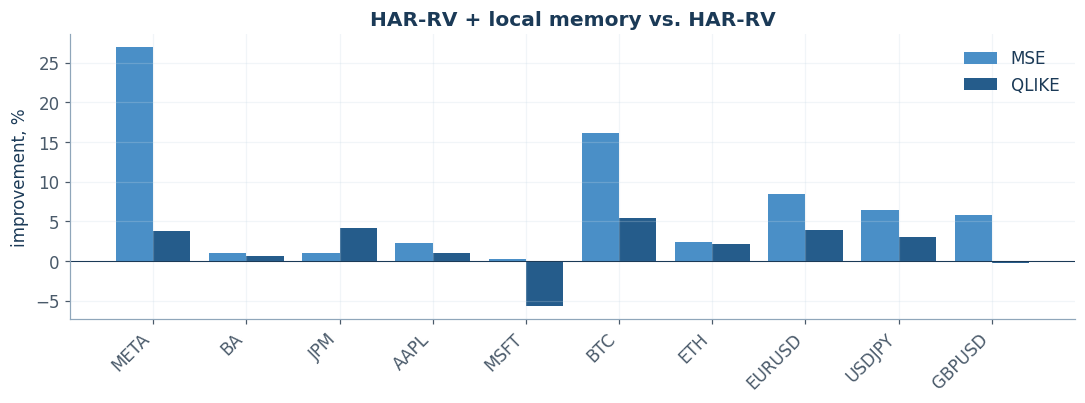

In [7]:
h = pd.read_csv(os.path.join(RES, 'har_memory_comparison.csv')).set_index('asset').reindex(ASSETS)
tab = h[['mse_gain_%', 'qlike_gain_%']].copy()
tab.columns = ['dMSE, %', 'dQLIKE, %']
display(tab.round(2))
print('assets with MSE gain > 0 :', int((tab['dMSE, %'] > 0).sum()), 'of 10')
print('assets with QLIKE gain > 0:', int((tab['dQLIKE, %'] > 0).sum()), 'of 10')
print('mean dMSE  : %+.1f %%' % tab['dMSE, %'].mean())
print('mean dQLIKE: %+.1f %%' % tab['dQLIKE, %'].mean())

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(ASSETS)); w = .4
ax.bar(x - w/2, tab['dMSE, %'].values, w, color=MID, label='MSE')
ax.bar(x + w/2, tab['dQLIKE, %'].values, w, color=BLUE, label='QLIKE')
ax.axhline(0, color=INK, lw=.7)
ax.set_xticks(x); ax.set_xticklabels(ASSETS, rotation=45, ha='right')
ax.set_ylabel('improvement, %'); ax.set_title('HAR-RV + local memory vs. HAR-RV')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'nb_har_improvement.png')); plt.show()

---
## Result 5 — static attention mechanisms degrade when memory strengthens

Three architectures (Standard, ProbSparse, MultiFeature) were trained on the same data and
evaluated separately in low-memory and high-memory regimes. All of them lose accuracy, but by
different amounts — and the sparsest mechanism, which is the best in calm markets, suffers
the most:

| mechanism | RMSE (low memory) | RMSE (high memory) | degradation |
|---|---|---|---|
| Standard | 1.078 | 1.628 | **+51 %** |
| ProbSparse | 0.415 | 1.006 | **+143 %** |
| MultiFeature | 0.608 | 0.911 | **+50 %** |

ProbSparse throws away exactly the long dependencies that carry the information in the
high-memory regime. This quantitative failure of static attention is the motivation for
Memory-Adaptive Attention, where the mask `M(d̂_t)` widens or narrows the context window
according to the local memory strength.

regime,all,high-memory,low-memory,"degradation, %"
mechanism,,,,
Standard,1.299,1.628,1.078,50.989
ProbSparse,0.699,1.006,0.415,142.818
MultiFeature,0.762,0.911,0.608,49.839


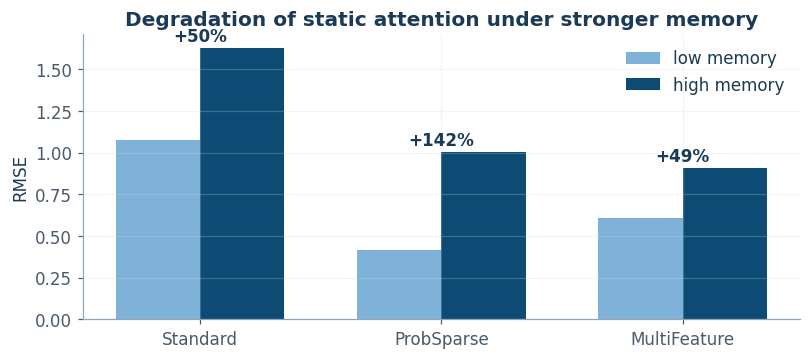

In [8]:
ar = pd.read_csv(os.path.join(RES, 'attention_regimes.csv'))
piv = ar.pivot(index='mechanism', columns='regime', values='RMSE').loc[['Standard', 'ProbSparse', 'MultiFeature']]
piv['degradation, %'] = 100 * (piv['high-memory'] - piv['low-memory']) / piv['low-memory']
display(piv.round(3))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(piv)); w = .35
ax.bar(x - w/2, piv['low-memory'].values, w, color=SOFT, label='low memory')
ax.bar(x + w/2, piv['high-memory'].values, w, color=NAVY, label='high memory')
for i, v in enumerate(piv['degradation, %'].values):
    ax.text(i, piv['high-memory'].values[i] + .04, '+%d%%' % v, ha='center', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(piv.index)
ax.set_ylabel('RMSE'); ax.set_title('Degradation of static attention under stronger memory')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'nb_attention_degradation.png')); plt.show()

---
## Practical part — from a volatility forecast to VaR / ES

The volatility model feeds directly into market-risk measures. For a normal law,
`VaR = z_α σ` and `ES = φ(z_α)/α · σ`; with heavy tails (Student's t) the same numbers are
considerably larger, which is exactly why static volatility models "under-report" risk in
crises — the same mechanism that we detect with the CUSUM test.

In [9]:
from math import erf, sqrt

Z = {'normal': (1.6449, 2.0627), 't(5)': (2.0150, 2.8902), 't(3)': (2.3534, 3.8757)}

rows = []
for sigma in (0.008, 0.012, 0.020, 0.030):
    for name, (z, es_mult) in Z.items():
        rows.append({'sigma': sigma, 'distribution': name,
                     'VaR, %': 100 * z * sigma, 'ES, %': 100 * es_mult * sigma})
risk = pd.DataFrame(rows)
display(risk.round(3))

,sigma,distribution,"VaR, %","ES, %"
0,0.008,normal,1.316,1.650
1,0.008,t(5),1.612,2.312
2,0.008,t(3),1.883,3.101
3,0.012,normal,1.974,2.475
4,0.012,t(5),2.418,3.468
5,0.012,t(3),2.824,4.651
6,0.020,normal,3.290,4.125
7,0.020,t(5),4.030,5.780
8,0.020,t(3),4.707,7.751
9,0.030,normal,4.935,6.188


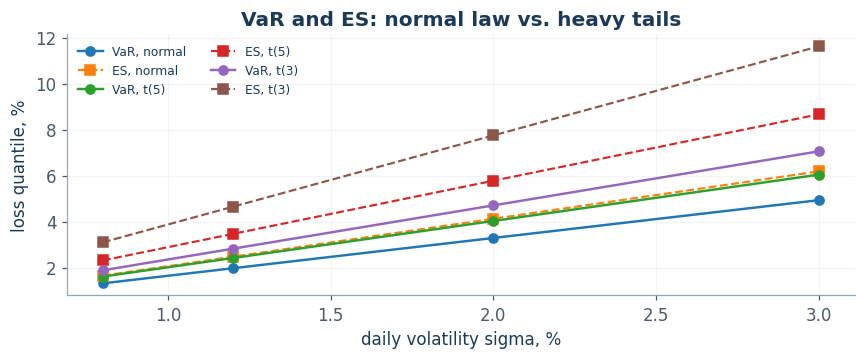

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.4))
sig = np.array(sorted(risk['sigma'].unique()))
for name, (z, es_mult) in Z.items():
    ax.plot(100 * sig, 100 * z * sig, marker='o', lw=1.6, label='VaR, ' + name)
    ax.plot(100 * sig, 100 * es_mult * sig, marker='s', ls='--', lw=1.4, label='ES, ' + name)
ax.set_xlabel('daily volatility sigma, %'); ax.set_ylabel('loss quantile, %')
ax.set_title('VaR and ES: normal law vs. heavy tails')
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(os.path.join(FIG, 'nb_var_es.png')); plt.show()

---
## Conclusions

1. **Long memory lives in volatility.** `d ∈ [0.42; 0.56]`, `H ≈ 0.90–0.95` for realized
   volatility, while returns have `d ≈ 0`.
2. **The memory is non-stationary.** Significant structural shifts for 7 of 10 assets; on
   average `d` falls from 0.52 to 0.45 in crisis periods.
3. **Local memory is informative.** HAR-RV with `d̂_t` and `Δd̂_t` improves MSE for all
   10 assets (+7.1 %) and QLIKE for 8 of 10 (+1.8 %).
4. **Static attention is not enough.** Every fixed attention scheme degrades when the memory
   strengthens — ProbSparse by 143 % — which motivates the adaptive mask `M(d̂_t)`.

**Next steps:** a differentiable memory estimator inside the transformer, an extended asset
base with intraday data, and a full VaR/ES backtest (Kupiec / Christoffersen) of the adaptive
model.